# PathSnap - 02 Candidates, Labels and Features

**Partitions used:** `train` (80 trips) to choose the candidate radius / K; `student_test` (10 trips) only to report the same statistics.
The evaluator partition is never used.

Pipeline (code in `src/features.py`):
1. **Prepare** each trip: project to local metres, split at time gaps > 60 s into independent segments, compute GPS speed / heading
   by central differences inside a segment, de-duplicate identical `(u,v)` arcs and drop zero-length arcs.
2. **Candidates**: road arcs within radius **R** of each GPS point, keeping the **K** nearest.
3. **Labels**: the `.route` file is an ordered list of arcs with *no* link to GPS points. We align it with dynamic programming:
   each point gets a route position `j(i)`, non-decreasing in time, minimising the total point-to-arc distance.
   If the aligned arc is more than 50 m away, the point gets **no label** (-1): the reference is unreliable there (see EDA: trips 33, 54).
4. **Features** per (point, candidate) use only GPS + road network, so the API can compute them without the route.
   Candidate label = 1 if it is the point's aligned arc.

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import folium

sys.path.insert(0, str(Path.cwd().parent / "src"))
from data import PARTITIONS, list_trips, load_trip
import features as F

OUT = Path.cwd().parent / "outputs" / "features"
(OUT / "plots").mkdir(parents=True, exist_ok=True); (OUT / "maps").mkdir(parents=True, exist_ok=True)
print("GAP_SPLIT_S", F.GAP_SPLIT_S, "| LABEL_MAX_DIST", F.LABEL_MAX_DIST, "| RADIUS", F.RADIUS, "| MAX_CANDS", F.MAX_CANDS)

GAP_SPLIT_S 60.0 | LABEL_MAX_DIST 50.0 | RADIUS 50.0 | MAX_CANDS 8


## 1. Wide candidate set for choosing R and K
Build candidates with a generous R = 100 m, K = 50 for every trip; from these we can compute the miss rate for any smaller (R, K).

In [2]:
t0 = time.time()
wide = {p: [] for p in PARTITIONS}; pts = {p: [] for p in PARTITIONS}
for part in PARTITIONS:
    for tid in list_trips(part):
        c, pt = F.build_trip(part, tid, radius=100, k=50)
        wide[part].append(c[["trip_id", "point_idx", "dist", "dist_rank", "label"]]); pts[part].append(pt)
wide = {p: pd.concat(v, ignore_index=True) for p, v in wide.items()}
pts = {p: pd.concat(v, ignore_index=True) for p, v in pts.items()}
print(f"built in {time.time()-t0:.0f}s")

built in 19s


## 2. Label quality (route-to-GPS alignment)

In [3]:
allp = pd.concat(pts.values())
lq = allp.groupby(["partition", "trip_id"]).agg(points=("point_idx", "size"), labeled_frac=("true_arc", lambda s: (s >= 0).mean()),
                                                align_median_m=("align_dist", "median"), align_p95_m=("align_dist", lambda s: s.quantile(.95)),
                                                segments=("seg_id", "nunique")).reset_index()
lq.to_csv(OUT / "label_quality_per_trip.csv", index=False)
print(lq.groupby("partition")[["points", "labeled_frac", "align_median_m", "segments"]].describe().round(3).T)
for p, g in allp.groupby("partition"):
    print(f"{p}: {(g.true_arc >= 0).mean():.2%} of {len(g):,} points labeled")
lq.sort_values("labeled_frac").head(6)

partition             student_test      train
points         count        10.000     80.000
               mean       1916.000   2605.212
               std        1335.432   3312.345
               min         262.000    361.000
               25%         917.750    945.750
               50%        1420.000   1529.000
               75%        2872.000   2792.750
               max        3958.000  19313.000
labeled_frac   count        10.000     80.000
               mean          0.999      0.975
               std           0.002      0.120
               min           0.993      0.106
               25%           1.000      0.999
               50%           1.000      1.000
               75%           1.000      1.000
               max           1.000      1.000
align_median_m count        10.000     80.000
               mean          5.083      8.155
               std           0.911     19.911
               min           4.167      3.451
               25%           4.425

,partition,trip_id,points,labeled_frac,align_median_m,align_p95_m,segments
54,train,00000054,19313,0.105577,140.008729,209.605772,2
36,train,00000033,5844,0.411362,122.383217,142.022479,1
11,train,00000002,7243,0.880160,5.765411,242.221046,6
63,train,00000066,4325,0.909827,6.590270,65.402106,1
45,train,00000043,2322,0.928941,10.998763,70.033951,3
86,train,00000096,3271,0.955671,4.462432,20.282500,1


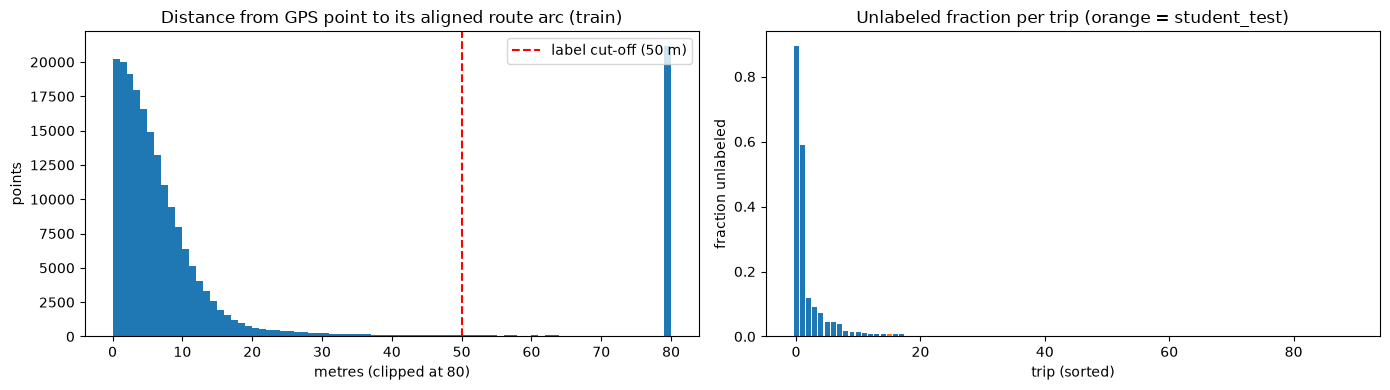

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
a = allp[allp.partition == "train"].align_dist
ax[0].hist(np.clip(a, 0, 80), bins=80); ax[0].axvline(F.LABEL_MAX_DIST, color="r", ls="--", label="label cut-off (50 m)")
ax[0].set(title="Distance from GPS point to its aligned route arc (train)", xlabel="metres (clipped at 80)", ylabel="points"); ax[0].legend()
s = lq.sort_values("labeled_frac")
ax[1].bar(range(len(s)), 1 - s.labeled_frac, color=["tab:orange" if p == "student_test" else "tab:blue" for p in s.partition])
ax[1].set(title="Unlabeled fraction per trip (orange = student_test)", xlabel="trip (sorted)", ylabel="fraction unlabeled")
plt.tight_layout(); plt.savefig(OUT / "plots/01_label_quality.png", dpi=130); plt.show()

## 3. Choosing the candidate radius R and K (train only)
**Candidate miss rate** = share of labeled points whose true arc is not in the candidate set.
Labeled points are by definition within 50 m of their arc, so R > 50 m cannot lower the miss rate; it only adds candidates.
Rule: R = 50 m and the smallest K with train miss rate < 1% (fewer candidates = smaller HMM state space).

In [5]:
def grid(part):
    c, p = wide[part], pts[part]
    lab = p[p.true_arc >= 0].set_index(["trip_id", "point_idx"])
    L = lab.join(c[c.label == 1].set_index(["trip_id", "point_idx"])[["dist", "dist_rank"]])
    rows = []
    for R in [20, 30, 40, 50, 75, 100]:
        within = c[c.dist <= R].groupby(["trip_id", "point_idx"]).size()
        for K in [3, 5, 8, 10, 15, 20]:
            hit = (L.dist <= R) & (L.dist_rank < K)
            rows.append({"R": R, "K": K, "miss_rate": 1 - hit.mean(), "avg_cands": np.minimum(within, K).sum() / len(p)})
    return pd.DataFrame(rows)

g_tr, g_te = grid("train"), grid("student_test")
g_tr.to_csv(OUT / "radius_k_grid_train.csv", index=False); g_te.to_csv(OUT / "radius_k_grid_student_test.csv", index=False)
print("TRAIN miss rate"); print(g_tr.pivot(index="R", columns="K", values="miss_rate").round(4))
print("TRAIN avg candidates / point"); print(g_tr.pivot(index="R", columns="K", values="avg_cands").round(2))

TRAIN miss rate
K        3       5       8       10      15      20
R                                                  
20   0.0733  0.0481  0.0400  0.0388  0.0378  0.0373
30   0.0572  0.0295  0.0194  0.0178  0.0163  0.0156
40   0.0506  0.0220  0.0111  0.0092  0.0075  0.0064
50   0.0488  0.0198  0.0086  0.0066  0.0048  0.0030
75   0.0488  0.0198  0.0086  0.0066  0.0048  0.0030
100  0.0488  0.0198  0.0086  0.0066  0.0048  0.0030
TRAIN avg candidates / point
K      3     5     8     10     15     20
R                                        
20   2.19  2.84  3.30  3.43   3.56   3.60
30   2.38  3.33  4.19  4.51   4.93   5.10
40   2.48  3.62  4.78  5.30   6.10   6.52
50   2.54  3.80  5.21  5.90   7.08   7.81
75   2.67  4.13  5.96  6.97   8.95  10.41
100  2.84  4.43  6.52  7.75  10.38  12.51


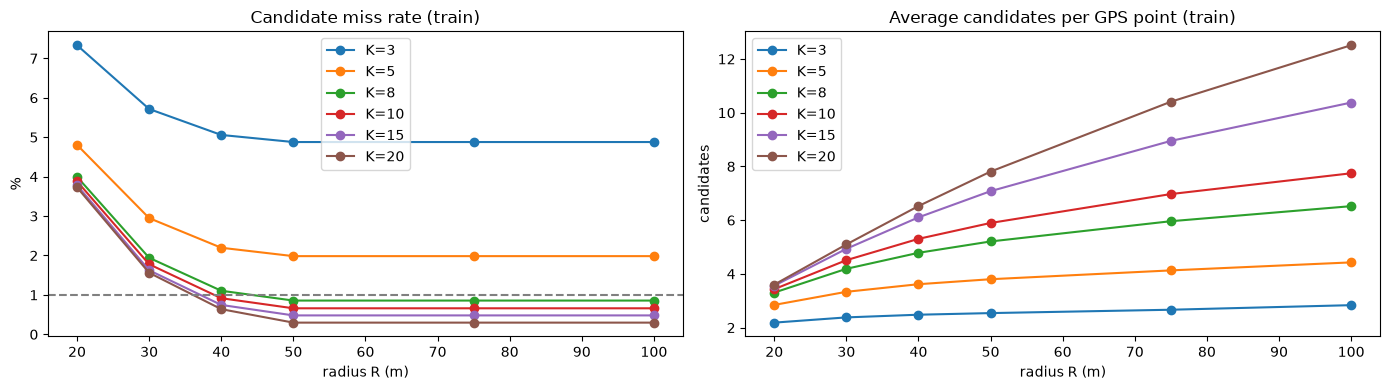

chosen: R=50 m, K=8  train miss=0.86%, avg cands=5.2
student_test at same setting: miss=0.26%, avg cands=5.9


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for K, g in g_tr.groupby("K"):
    ax[0].plot(g.R, g.miss_rate * 100, marker="o", label=f"K={K}")
    ax[1].plot(g.R, g.avg_cands, marker="o", label=f"K={K}")
ax[0].axhline(1, color="grey", ls="--"); ax[0].set(title="Candidate miss rate (train)", xlabel="radius R (m)", ylabel="%")
ax[1].set(title="Average candidates per GPS point (train)", xlabel="radius R (m)", ylabel="candidates")
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(OUT / "plots/02_radius_k_selection.png", dpi=130); plt.show()

sel = g_tr[(g_tr.R == F.LABEL_MAX_DIST) & (g_tr.miss_rate < 0.01)].sort_values("K").iloc[0]
print(f"chosen: R={sel.R:.0f} m, K={sel.K:.0f}  train miss={sel.miss_rate:.2%}, avg cands={sel.avg_cands:.1f}")
te = g_te[(g_te.R == sel.R) & (g_te.K == sel.K)].iloc[0]
print(f"student_test at same setting: miss={te.miss_rate:.2%}, avg cands={te.avg_cands:.1f}")
assert (sel.R, sel.K) == (F.RADIUS, F.MAX_CANDS), "update RADIUS / MAX_CANDS in src/features.py"

## 4. Final feature tables (R, K from section 3)

In [7]:
t0 = time.time()
cand, point = {}, {}
for part in PARTITIONS:
    out = [F.build_trip(part, tid) for tid in list_trips(part)]
    cand[part] = pd.concat([o[0] for o in out], ignore_index=True)
    point[part] = pd.concat([o[1] for o in out], ignore_index=True)
    cand[part].to_parquet(OUT / f"candidates_{part}.parquet", index=False)
    point[part].to_parquet(OUT / f"points_{part}.parquet", index=False)
print(f"built in {time.time()-t0:.0f}s")

rows = []
for part in PARTITIONS:
    c, p = cand[part], point[part]; lab = p.true_arc >= 0
    rows.append({"partition": part, "trips": p.trip_id.nunique(), "gps_points": len(p), "labeled_points": int(lab.sum()),
                 "candidate_rows": len(c), "trainable_rows (label!=-1)": int((c.label >= 0).sum()),
                 "positive_rate": (c.label[c.label >= 0] == 1).mean(), "avg_cands_per_point": len(c) / len(p),
                 "points_without_candidates": (p.n_cands == 0).mean(),
                 "candidate_miss_rate": 1 - p.true_in_cands[lab].mean(),
                 "nearest_arc_top1_acc": (c[(c.dist_rank == 0) & (c.label >= 0)].label == 1).sum() / lab.sum()})
stats = pd.DataFrame(rows).set_index("partition").T
stats.to_csv(OUT / "feature_table_stats.csv"); stats

built in 20s


partition,train,student_test
trips,8.000000e+01,10.000000
gps_points,2.084170e+05,19160.000000
labeled_points,1.851620e+05,19133.000000
candidate_rows,1.085223e+06,113694.000000
trainable_rows (label!=-1),1.059294e+06,113634.000000
positive_rate,1.733003e-01,0.167943
avg_cands_per_point,5.206979e+00,5.933925
points_without_candidates,8.746407e-02,0.000000
candidate_miss_rate,8.565472e-03,0.002561
nearest_arc_top1_acc,5.527700e-01,0.529713


`nearest_arc_top1_acc` is a **non-ML baseline**: always pick the geometrically nearest arc. The classifiers in Step 3 must beat it.
Its main failure mode is two-way roads, where both directions are at the same distance, so heading is what decides it.

## 5. Feature distributions by class (train, labeled rows)

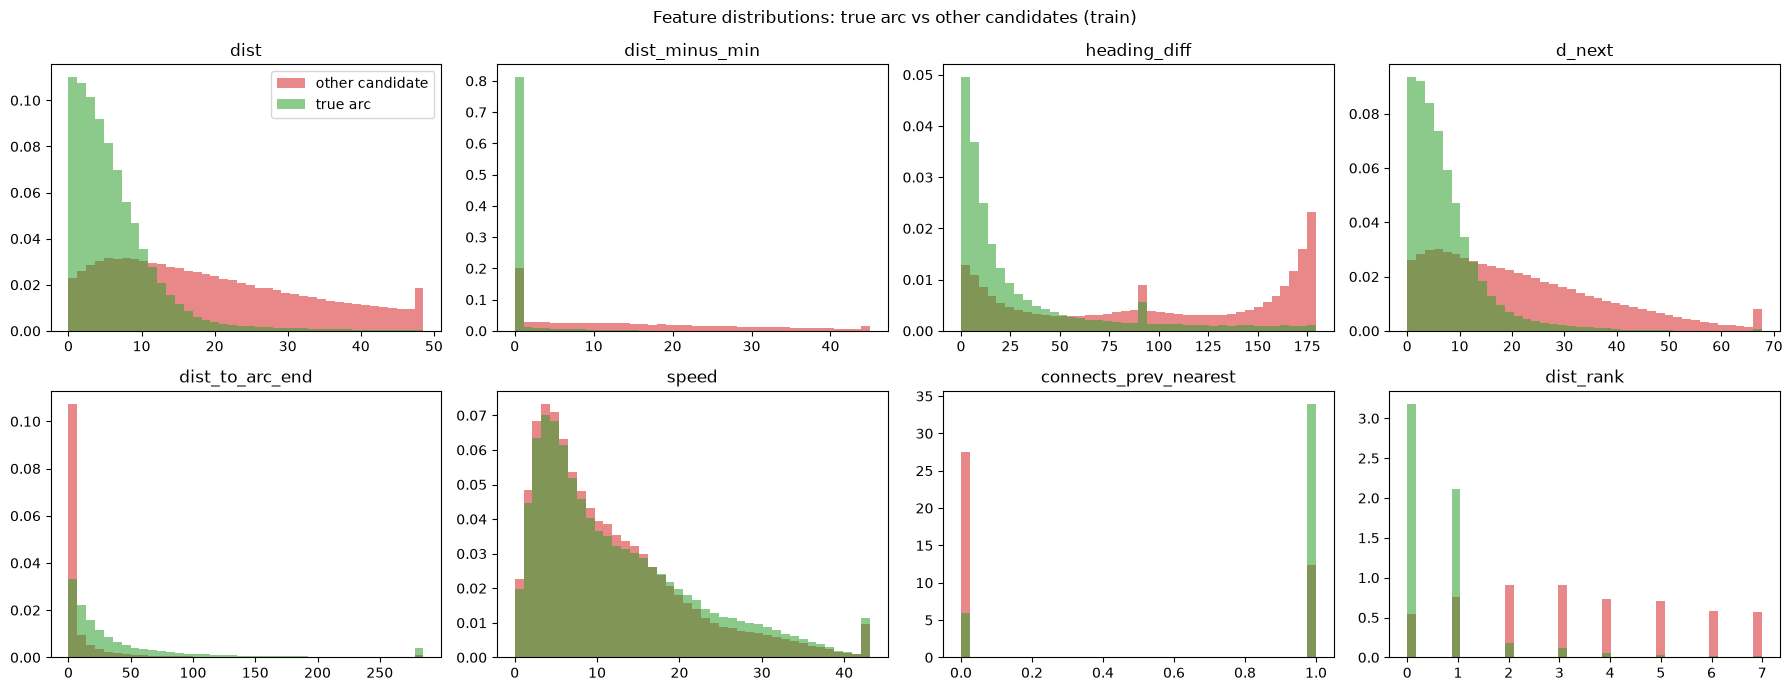

label                       0        1
dist                   19.649    6.304
dist_rank               3.375    0.594
dist_minus_min         14.206    0.625
dist_ratio              4.772    0.936
n_cands                 7.014    5.701
heading_diff           98.736   31.555
speed                  11.606   12.532
arc_len                96.627  209.382
proj_frac               0.499    0.501
dist_to_arc_end        13.087   51.657
two_way                 0.757    0.700
out_deg                 2.090    2.026
in_deg                  2.088    2.026
d_prev                 21.919    7.579
d_next                 21.914    7.533
d_prev2                26.206   10.861
d_next2                26.190   10.761
same_as_prev_nearest    0.109    0.470
connects_prev_nearest   0.311    0.850


In [8]:
tr = cand["train"][cand["train"].label >= 0]
show = ["dist", "dist_minus_min", "heading_diff", "d_next", "dist_to_arc_end", "speed", "connects_prev_nearest", "dist_rank"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, f in zip(axes.ravel(), show):
    hi = tr[f].quantile(.99)
    for lbl, col in [(0, "tab:red"), (1, "tab:green")]:
        ax.hist(np.clip(tr[tr.label == lbl][f], None, hi), bins=40, alpha=.55, density=True, color=col, label="true arc" if lbl else "other candidate")
    ax.set_title(f)
axes[0, 0].legend(); plt.suptitle("Feature distributions: true arc vs other candidates (train)")
plt.tight_layout(); plt.savefig(OUT / "plots/03_feature_distributions.png", dpi=130); plt.show()
print(tr.groupby("label")[F.FEATURES].mean().T.round(3))

## 6. Sanity map: labels and the nearest-arc baseline
Points are **green** where the nearest arc is already the true arc, **red** where the nearest arc is wrong (the cases the classifier/HMM must fix),
**grey** where the point has no reliable label.

In [9]:
ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"

def label_map(part, tid, max_pts=4000):
    trip = load_trip(part, tid); tr_, nd, ar = trip["track"], trip["nodes"], trip["arcs"]
    c = cand[part][cand[part].trip_id == tid]; p = point[part][point[part].trip_id == tid]
    top = c[c.dist_rank == 0].set_index("point_idx").label.reindex(p.point_idx).values   # NaN = no candidates
    status = np.where(p.true_arc.values < 0, -1, (top == 1).astype(int))
    m = folium.Map(tiles=None); folium.TileLayer(ESRI, attr="Tiles &copy; Esri", name="Esri street map").add_to(m)
    rt = folium.FeatureGroup("Reference route")
    folium.PolyLine([[[nd.lat[i], nd.lon[i]], [nd.lat[j], nd.lon[j]]] for i, j in ar.iloc[trip["route"].arc_id].values],
                    color="green", weight=5, opacity=.6).add_to(rt); rt.add_to(m)
    groups = {1: folium.FeatureGroup("nearest arc = true arc"), 0: folium.FeatureGroup("nearest arc WRONG"),
              -1: folium.FeatureGroup("no label / no candidate")}
    colors = {1: "#1a9850", 0: "#d73027", -1: "#888"}
    step = max(1, len(tr_) // max_pts)
    for i in range(0, len(tr_), step):
        k = int(status[i])
        folium.CircleMarker([tr_.lat[i], tr_.lon[i]], radius=3, color=colors[k], fill=True, weight=0, fill_opacity=.9,
                            tooltip=f"i={i} cands={p.n_cands.iloc[i]}").add_to(groups[k])
    for g in groups.values(): g.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    m.fit_bounds([[tr_.lat.min(), tr_.lon.min()], [tr_.lat.max(), tr_.lon.max()]])
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px;border:1px solid #888;font:13px sans-serif">'
        f'<b>{part}/{tid}</b><br><span style="color:green">&#9644;</span> reference route<br><span style="color:#1a9850">&#9679;</span> nearest arc correct<br>'
        f'<span style="color:#d73027">&#9679;</span> nearest arc wrong<br><span style="color:#888">&#9679;</span> unlabeled</div>'))
    m.save(OUT / "maps" / f"labels_{part}_{tid}.html"); return m

label_map("train", "00000002")
label_map("student_test", "00000000")